# Denoising

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import skimage.io as io
from skimage.util import img_as_float, random_noise
from skimage.color import rgb2gray
from skimage.filters import gaussian, median
from skimage.transform import resize
from scipy.ndimage import convolve
from numpy.fft import fft2, fftshift, ifftshift, ifft2
from skimage.restoration import denoise_tv_chambolle
from mpl_toolkits.axes_grid1.inset_locator import zoomed_inset_axes

plt.style.use('../../src/bip.mplstyle')

In [2]:
# Specific display
def display(images, filename):
    
    # Prepare figure
    fig, axs = plt.subplots(2, 2, figsize=(10,10))
    axs = axs.ravel()
    
    # Display each image in an axe
    for k, image in enumerate(images):
        img, title = image
        
        # Image
        axs[k].imshow(img, "gray")
        axs[k].set_xticks([])
        axs[k].set_yticks([])
        axs[k].set_title(title, fontsize=16)

        # Zoom
        axin = zoomed_inset_axes(axs[k], zoom=2.5, loc="lower right")
        axin.imshow(img[17:47,58:88], "gray")
        axin.set_xticks([])
        axin.set_yticks([])

    # Save & show
    fig.savefig(filename, bbox_inches='tight')
    plt.show()

## Mean & median filters

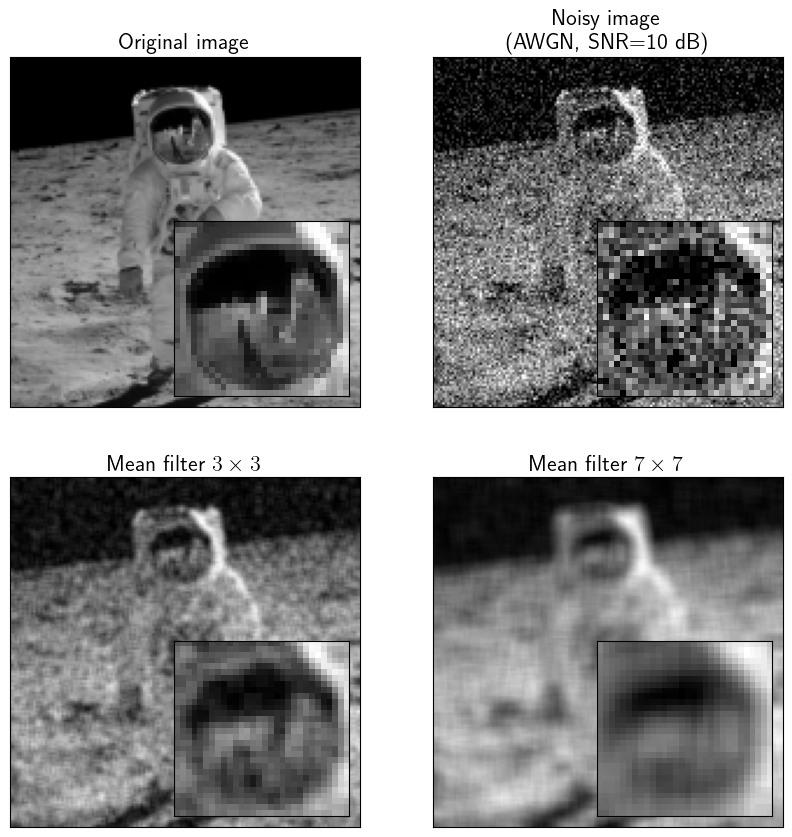

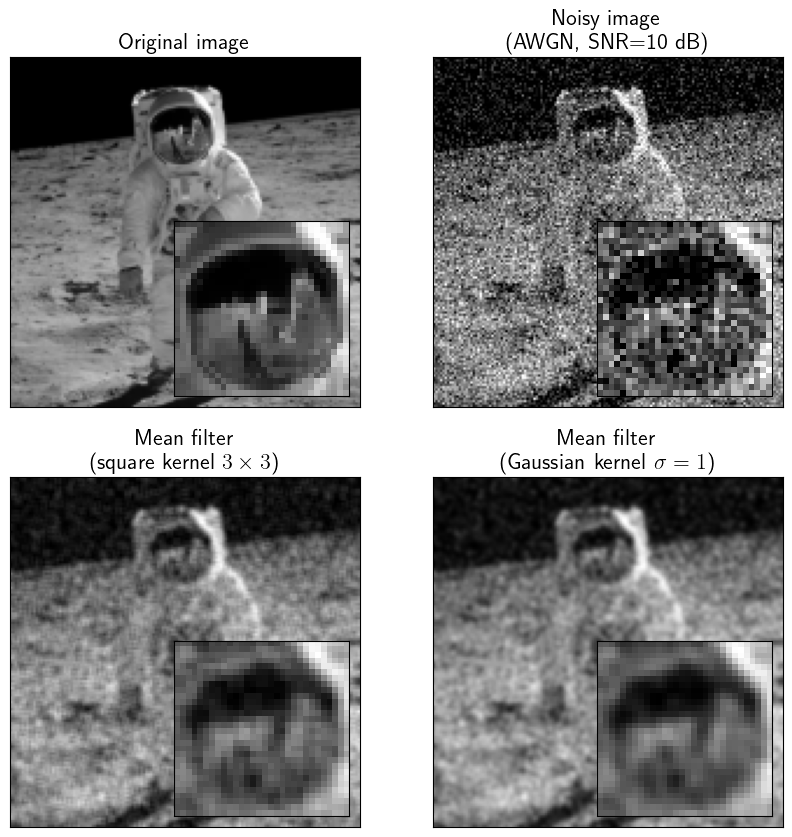

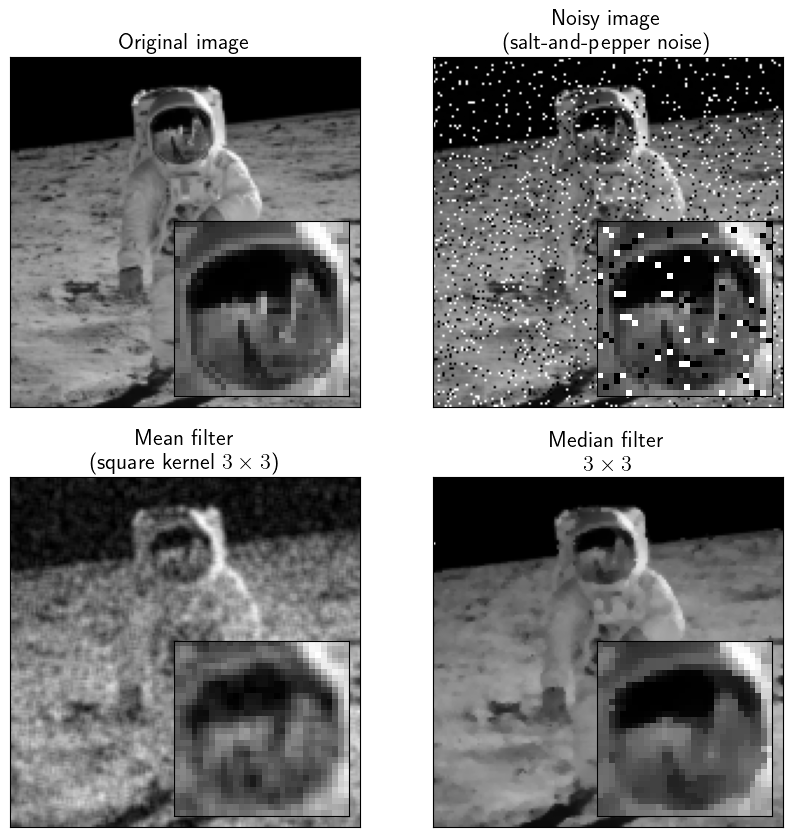

In [3]:
def square_footprint(s):
    return np.ones((s,s)) / s**2

# Original image
original = io.imread('../../src/figs/aldrin.png')
original = rgb2gray(original)
original = resize(original, (150, 150), order=1, anti_aliasing=True)
original = img_as_float(original)

# Image with Gaussian noise
gaussian_noisy = random_noise(original, mode='gaussian', clip=True, var=.025)
noise = gaussian_noisy - original
snr = 10 * np.log10( np.mean(original**2) / np.mean(noise**2) )

# Salt-and-pepper noise
sp_noisy = random_noise(original, mode='s&p', clip=True, amount=.1)

# Mean filter (square kernel)
mean_filter_3 = convolve(gaussian_noisy, square_footprint(3))
mean_filter_5 = convolve(gaussian_noisy, square_footprint(5))
mean_filter_7 = convolve(gaussian_noisy, square_footprint(7))

# Mean filter (Gaussian kernel)
gaussian_filter_1 = gaussian(gaussian_noisy,1)

# Median filter
median_filter_3 = median(sp_noisy, square_footprint(3))

# Mean filter
display((
    ( original,        "Original image" ),
    ( gaussian_noisy, f"Noisy image\n(AWGN, SNR={snr:.0f} dB)"),
    ( mean_filter_3,  r"Mean filter $3\times3$" ),
    ( mean_filter_7,  r"Mean filter $7\times7$" )),
    "mean-filter-size.svg")

# Mean filter with different footprints
display((
    ( original,           "Original image" ),
    ( gaussian_noisy,     f"Noisy image\n(AWGN, SNR={snr:.0f} dB)" ),
    ( mean_filter_3,      "Mean filter\n"r"(square kernel $3\times3$)" ),
    ( gaussian_filter_1,  "Mean filter\n"r"(Gaussian kernel $\sigma=1$)" )),
    "mean-filter-kernels.svg")

# Median filter vs mean filter
display((
    ( original,        "Original image" ),
    ( sp_noisy,        "Noisy image\n(salt-and-pepper noise)" ),
    ( mean_filter_3,   "Mean filter\n"r"(square kernel $3\times3$)" ),
    ( median_filter_3, "Median filter\n"r"$3\times3$" )),
    "median-vs-mean.svg")

## Periodic noise

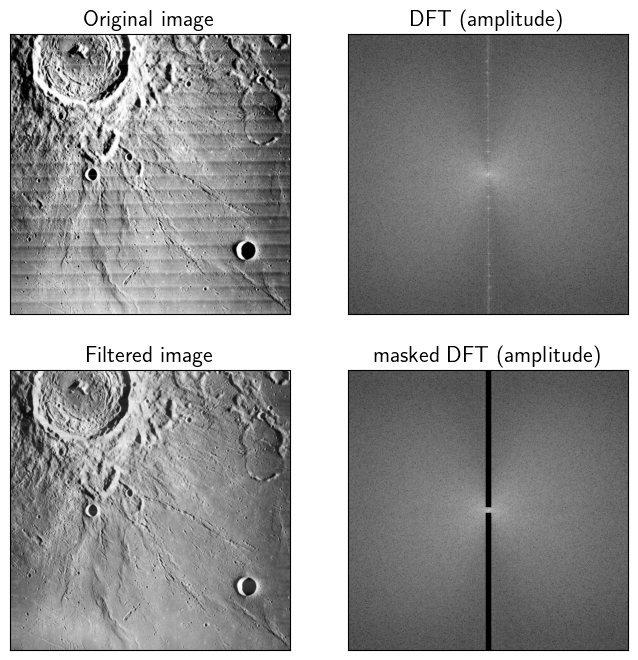

In [4]:
img = io.imread('../../src/figs/lo1_m31.jpg')
img = img[20:520,20:520]

F = fftshift(fft2(img))

mask = np.ones(F.shape)
mask[:245,245:255] = 1e-9
mask[255:,245:255] = 1e-9
G = F*mask

res = np.real(ifft2(ifftshift(G)))

fig, axs = plt.subplots(2,2,figsize=(8,8))
axs = axs.ravel()
axs[0].imshow(img, cmap="gray")
axs[0].set_title('Original image', fontsize=16)
axs[1].imshow(20*np.log10(abs(F)), cmap="gray", vmin=23, vmax=151)
axs[1].set_title('DFT (amplitude)', fontsize=16)
axs[3].imshow(20*np.log10(abs(G)), cmap="gray", vmin=23, vmax=151)
axs[3].set_title('masked DFT (amplitude)', fontsize=16)
axs[2].imshow(res, cmap="gray")
axs[2].set_title('Filtered image', fontsize=16)
for i in range(4):
    axs[i].set_xticks([])
    axs[i].set_yticks([])
plt.savefig("periodic-noise.svg", bbox_inches='tight')
plt.show()

(740, 560)
0 1


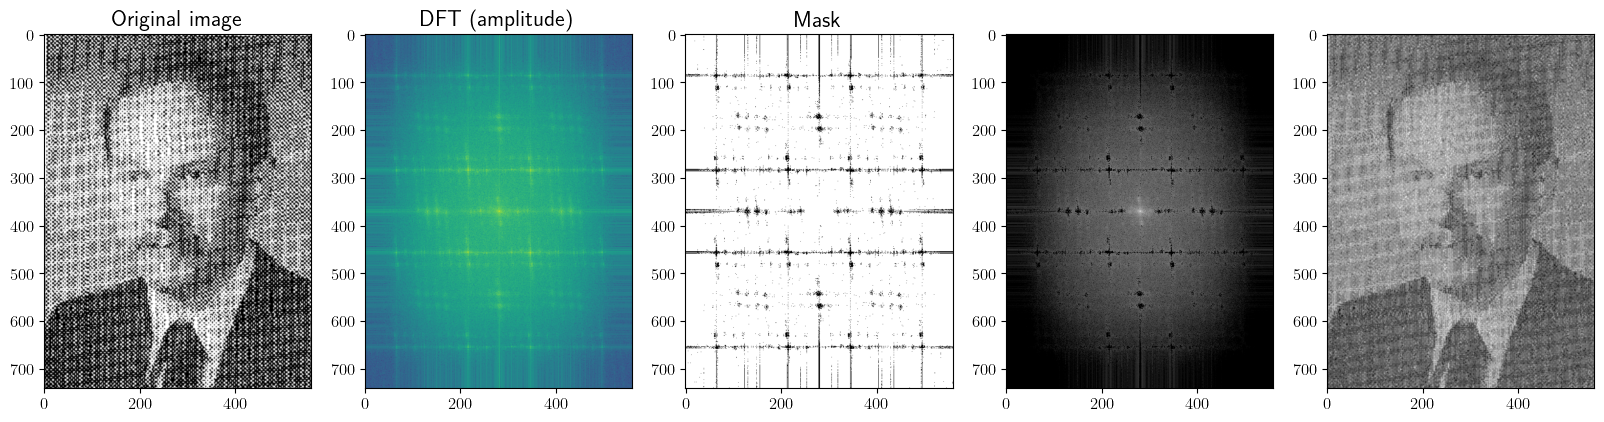

In [5]:
img = io.imread('theriault.png')
img = img[50:790,40:600]
img = rgb2gray(img)
print(img.shape)

F = fftshift(fft2(img))

from skimage.filters import threshold_local
X = 20*np.log10(abs(F))
T = threshold_local(X, 101, offset=-10)
Mask = (X<T)*1
Mask[340:400,250:310] = 1

# Mask = T>30

# Mask = np.ones(F.shape)
# Mask[280:290,:] = 0
# Mask[450:460,:] = 0
# Mask[360:380,:220] = 0
# Mask[360:380,330:] = 0

print(Mask.min(), Mask.max())
Y = F*Mask + 1e-12

y = np.real(ifft2(ifftshift(Y)))

fig, axs = plt.subplots(1,5,figsize=(20,5))
axs[0].imshow(img, cmap="gray")
axs[0].set_title('Original image', fontsize=16)
axs[1].imshow(20*np.log10(abs(F)))
axs[1].set_title('DFT (amplitude)', fontsize=16)
axs[2].imshow(Mask, cmap="gray")
axs[2].set_title('Mask', fontsize=16)
axs[3].imshow(20*np.log10(abs(Y)), cmap="gray", vmin=5)
axs[3].set_title('', fontsize=16)
axs[4].imshow(y, cmap="gray")
axs[4].set_title('', fontsize=16)
plt.show()

# TV regularisation

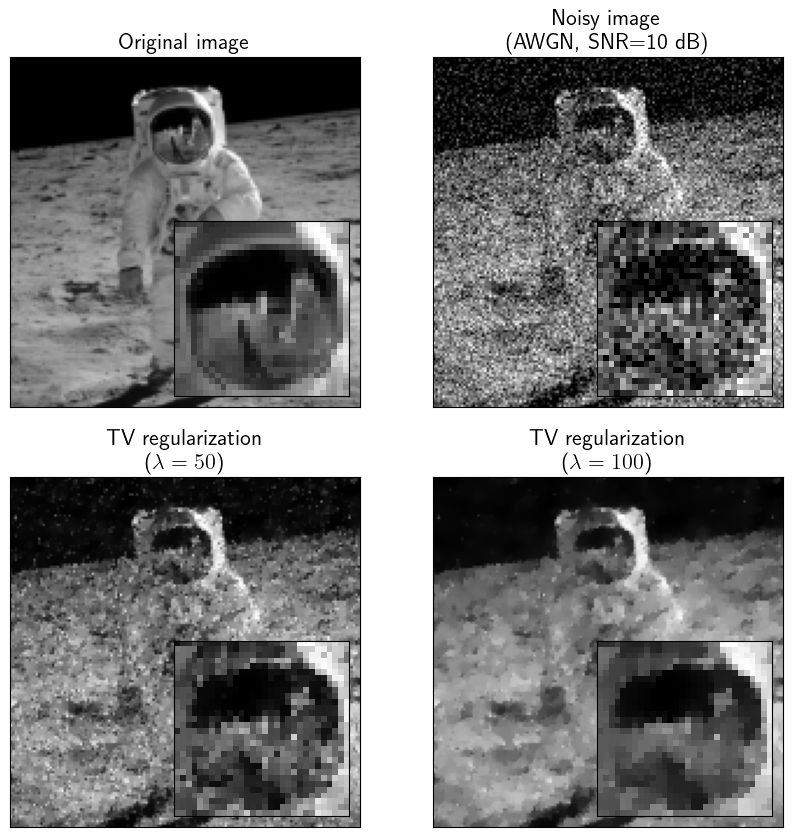

In [6]:
img = io.imread('../../src/figs/aldrin.png')
img = rgb2gray(img)
img = resize(img, (150, 150), order=1, anti_aliasing=True)
img = img_as_float(img)

obs = random_noise(img, mode='gaussian', clip=True, var=.025)
noise = obs - img
snr = 10 * np.log10( np.mean(img**2) / np.mean(noise**2) )

lbd1 = 50
restored_1 = denoise_tv_chambolle(obs, weight=lbd1/1000)

lbd2 = 100
restored_2 = denoise_tv_chambolle(obs, weight=lbd2/1000)

display((
    ( img,         "Original image" ),
    ( obs,        f"Noisy image\n(AWGN, SNR={snr:.0f} dB)" ),
    ( restored_1, f"TV regularization\n"rf"($\lambda = {lbd1}$)" ),
    ( restored_2, f"TV regularization\n"rf"($\lambda = {lbd2}$)" )),
    "tv-denoising.svg")